# Wire Bonding SPC-AI Analysis

This notebook presents the complete analysis used in the Wire Bonding SPC-AI project.

The analysis follows the research design:

**Historical SPC Data → Data Preparation → Study Population Selection → SPC + Nelson Rules → Feature Engineering → ARIMA + MLP Fork → Model Evaluation → Hybrid Decision Support**

The analysis uses three wire-bond Critical to Quality measurements:

- Wire Pull (WP)
- Ball Shear (BS)
- Stitch Pull (SP)

ARIMA and MLP operate as independent predictive branches.

ARIMA forecasts the future standardized SPC trend, while MLP predicts the future process state at the fifth subsequent event.

The two outputs are combined only at the decision stage.

In [7]:
%matplotlib inline

from pathlib import Path
import sys
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# ---------------------------------------------------------
# Find project root
# ---------------------------------------------------------

def find_project_root():
    current = Path.cwd().resolve()

    for folder in [current] + list(current.parents):
        if (folder / "config.py").exists() and (folder / "src").exists():
            return folder

    raise FileNotFoundError(
        "Cannot find WirebondingSPC project root. "
        "Save this notebook inside the WirebondingSPC folder."
    )

PROJECT_ROOT = find_project_root()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# ---------------------------------------------------------
# Project modules
# ---------------------------------------------------------

from config import DATA_FILE

from src.data_cleaning import (
    load_and_clean_data,
    select_study_population,
    build_eda_tables
)

from src.anonymization import anonymize_study

from src.spc import (
    apply_spc,
    nelson_rule_reference
)

from src.features import (
    build_features,
    chronological_split,
    derive_time_split_meta
)

from src.models import (
    train_arima,
    train_mlp,
    evaluate_fork,
    build_latest_status
)

# ---------------------------------------------------------
# Output folders
# ---------------------------------------------------------

EVIDENCE_DIR = PROJECT_ROOT / "outputs" / "notebook_evidence"
EVIDENCE_DIR.mkdir(parents=True, exist_ok=True)

MODEL_OUTPUT_DIR = PROJECT_ROOT / "outputs" / "models"
MODEL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------
# Helper to save figures
# ---------------------------------------------------------

def save_figure(fig, filename):
    path = EVIDENCE_DIR / filename
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print("Saved:", path)

print("Project root :", PROJECT_ROOT)
print("Data file    :", DATA_FILE)
print("Evidence dir :", EVIDENCE_DIR)

Project root : C:\Users\User\src\WirebondingSPC
Data file    : C:\Users\User\src\WirebondingSPC\data\SPC_Events_Anonymous.csv
Evidence dir : C:\Users\User\src\WirebondingSPC\outputs\notebook_evidence


# 1. Data Cleaning and Data Understanding

The first stage prepares the historical SPC data for analysis.

The dataset contains Wire Pull, Ball Shear and Stitch Pull records together with corresponding production and break-mode information.

The cleaning stage standardizes the data structure, converts the records into event-level observations and checks the records before SPC analysis is performed.

In [8]:
cleaned, cleaning_audit, normalization_audit = load_and_clean_data(DATA_FILE)

print("Cleaned dataset shape:", cleaned.shape)

print("\nCleaning Audit")
display(cleaning_audit)

print("\nNormalization Audit")
display(normalization_audit)

print("\nSample Cleaned Records")
display(cleaned.head())

Cleaned dataset shape: (8354, 45)

Cleaning Audit


,CTQ,SOURCE_EVENTS,DUPLICATE_EVENTS_REMOVED,INVALID_EVENTS_REMOVED,CLEAN_EVENTS,SOURCE_FORMAT
0,WP,2194,0,0,2194,ANONYMIZED_EVENT_LEVEL
1,BS,3567,0,0,3567,ANONYMIZED_EVENT_LEVEL
2,SP,2593,0,0,2593,ANONYMIZED_EVENT_LEVEL



Normalization Audit


,CTQ,FIELD,RAW_VALUE,STANDARDIZED_VALUE,ROWS



Sample Cleaned Records


,EVENT_ID,CTQ,TID,LOT_ID,DEVICE,PACKAGE,MACH_NO,WIRE_TYPE,WIRE_DIAMETER,DATE_TIME,...,BREAK_MODE_RAW_2,BREAK_MODE_RAW_3,BREAK_MODE_RAW_4,BREAK_MODE_RAW_5,MODE_A_COUNT,MODE_B_COUNT,MODE_C_COUNT,MODE_D_COUNT,MODE_E_COUNT,BREAK_MODE_PATTERN
0,EVT0000001,WP,REC_0000473,LOT_000038,DEV_0291,PKG064,MACH061,WT_03,2.0,2020-01-01 00:00:00,...,B,B,B,B,0,5,0,0,0,B/B/B/B/B
1,EVT0000002,WP,REC_0000001,LOT_000003,DEV_0006,PKG034,MACH026,WT_03,2.0,2020-04-24 17:43:17,...,B,B,B,B,0,5,0,0,0,B/B/B/B/B
2,EVT0000003,WP,REC_0000002,LOT_000003,DEV_0006,PKG034,MACH026,WT_03,2.0,2020-04-24 17:44:30,...,B,B,B,B,0,5,0,0,0,B/B/B/B/B
3,EVT0000004,WP,REC_0000003,LOT_000003,DEV_0006,PKG034,MACH026,WT_03,2.0,2020-04-24 17:45:37,...,B,B,B,B,0,5,0,0,0,B/B/B/B/B
4,EVT0000005,WP,REC_0000004,LOT_000003,DEV_0006,PKG034,MACH026,WT_03,2.0,2020-04-24 19:20:45,...,B,B,B,B,0,5,0,0,0,B/B/B/B/B


In [9]:
ctq_count = (
    cleaned["CTQ"]
    .value_counts()
    .rename_axis("CTQ")
    .reset_index(name="EVENTS")
)

display(ctq_count)

print("Total cleaned events:", ctq_count["EVENTS"].sum())

,CTQ,EVENTS
0,BS,3567
1,SP,2593
2,WP,2194


Total cleaned events: 8354


Saved: C:\Users\User\src\WirebondingSPC\outputs\notebook_evidence\01_cleaned_events_by_ctq.png


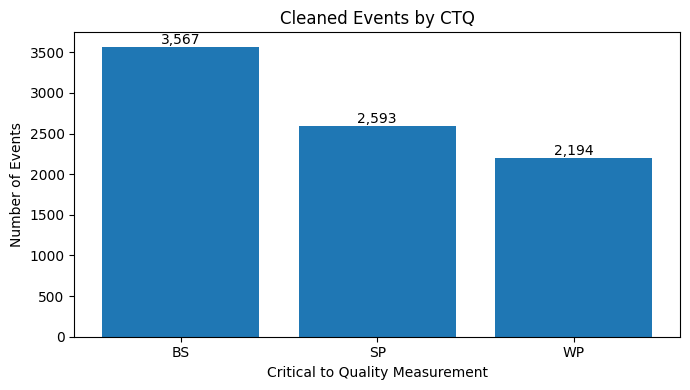

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.bar(
    ctq_count["CTQ"],
    ctq_count["EVENTS"]
)

ax.set_title("Cleaned Events by CTQ")
ax.set_xlabel("Critical to Quality Measurement")
ax.set_ylabel("Number of Events")

for i, value in enumerate(ctq_count["EVENTS"]):
    ax.text(
        i,
        value,
        f"{int(value):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

save_figure(
    fig,
    "01_cleaned_events_by_ctq.png"
)

plt.show()

# 2. Study Population Selection

A consistent study population is selected before comparing process behaviour between machines.

The population is selected using the Package, Wire Type and Wire Diameter combination with the highest usable number of records.

Machine ID is not used as a selection criterion. After the population is selected, all associated machines are retained.

The equipment identifiers are anonymized before analysis results are presented.

In [11]:
(
    study_raw,
    study_config_raw,
    population_audit,
    machine_population_raw
) = select_study_population(cleaned)

study, machine_map = anonymize_study(study_raw)

print("Selected study events :", len(study))
print("Anonymized machines   :", study["MACH_NO"].nunique())

display(population_audit.head(10))

Selected study events : 3346
Anonymized machines   : 17


CTQ,PACKAGE,WIRE_TYPE,WIRE_DIAMETER,WP,BS,SP,MIN_CTQ_EVENTS,TOTAL_EVENTS,ELIGIBLE
0,PKG103,WT_04,2.0,603,1387,1356,603,3346,True
1,PKG051,WT_04,2.0,129,211,213,129,553,True
2,PKG059,WT_03,2.0,185,205,34,34,424,False
3,PKG048,WT_04,2.0,71,130,128,71,329,False
4,PKG069,WT_03,2.0,109,153,55,55,317,False
5,PKG064,WT_03,2.0,150,140,21,21,311,False
6,PKG094,WT_04,2.0,54,104,102,54,260,False
7,PKG096,WT_04,2.0,46,99,99,46,244,False
8,PKG069,WT_03,4.0,104,113,9,9,226,False
9,PKG025,WT_04,2.0,0,101,96,0,197,False


In [12]:
selected_ctq = (
    study["CTQ"]
    .value_counts()
    .rename_axis("CTQ")
    .reset_index(name="EVENTS")
)

display(selected_ctq)

print("Total selected events:", selected_ctq["EVENTS"].sum())

,CTQ,EVENTS
0,BS,1387
1,SP,1356
2,WP,603


Total selected events: 3346


Saved: C:\Users\User\src\WirebondingSPC\outputs\notebook_evidence\02_selected_population_by_ctq.png


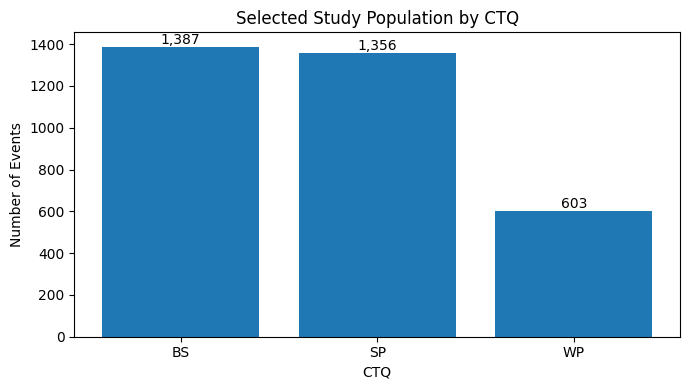

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.bar(
    selected_ctq["CTQ"],
    selected_ctq["EVENTS"]
)

ax.set_title("Selected Study Population by CTQ")
ax.set_xlabel("CTQ")
ax.set_ylabel("Number of Events")

for i, value in enumerate(selected_ctq["EVENTS"]):
    ax.text(
        i,
        value,
        f"{int(value):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

save_figure(
    fig,
    "02_selected_population_by_ctq.png"
)

plt.show()

In [14]:
machine_distribution = (
    study
    .groupby(["MACH_NO", "CTQ"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

for ctq in ["WP", "BS", "SP"]:
    if ctq not in machine_distribution.columns:
        machine_distribution[ctq] = 0

machine_distribution["TOTAL"] = (
    machine_distribution[["WP", "BS", "SP"]]
    .sum(axis=1)
)

machine_distribution = (
    machine_distribution
    .sort_values("TOTAL", ascending=False)
    .reset_index(drop=True)
)

display(machine_distribution)

CTQ,MACH_NO,BS,SP,WP,TOTAL
0,WB13,205,207,107,519
1,WB14,214,202,98,514
2,WB01,160,152,69,381
3,WB16,156,146,61,363
4,WB04,137,139,64,340
5,WB03,121,116,50,287
6,WB06,89,88,32,209
7,WB07,60,60,16,136
8,WB08,52,52,21,125
9,WB05,46,46,18,110


Saved: C:\Users\User\src\WirebondingSPC\outputs\notebook_evidence\02_machine_event_distribution.png


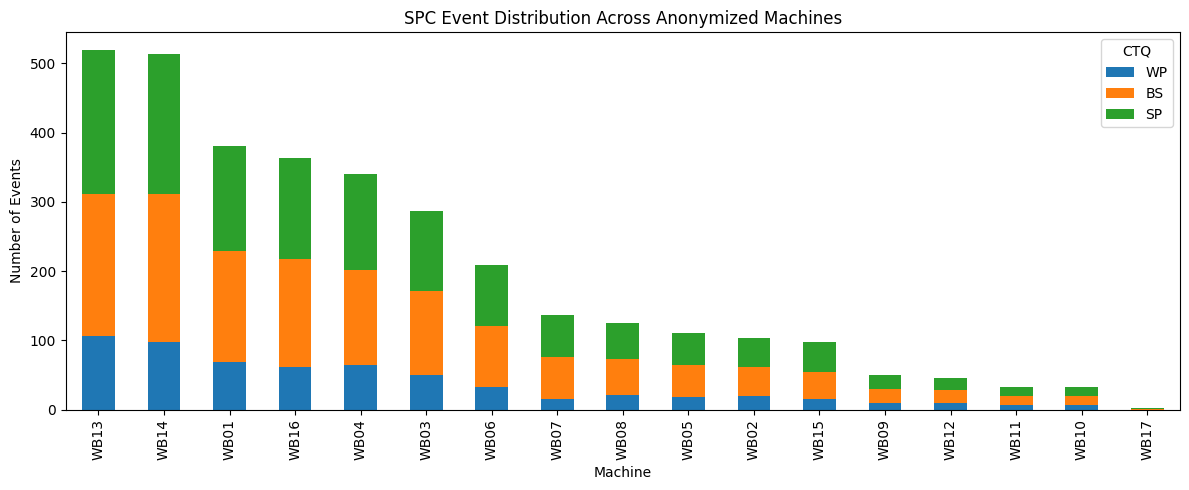

In [15]:
plot_df = (
    machine_distribution
    .set_index("MACH_NO")[["WP", "BS", "SP"]]
)

fig, ax = plt.subplots(figsize=(12, 5))

plot_df.plot(
    kind="bar",
    stacked=True,
    ax=ax
)

ax.set_title("SPC Event Distribution Across Anonymized Machines")
ax.set_xlabel("Machine")
ax.set_ylabel("Number of Events")
ax.legend(title="CTQ")

plt.tight_layout()

save_figure(
    fig,
    "02_machine_event_distribution.png"
)

plt.show()

# 3. SPC X̄–R and Nelson Rule Analysis

SPC analysis is performed separately for each Machine–CTQ stream.

The X̄ chart is used to monitor changes in the subgroup mean.

The R chart is used to monitor within-subgroup variation.

Nelson Rules N1 to N8 are applied together with the SPC limits to identify non-random process behaviour.

The SPC reference is established using historical training-period observations and is kept fixed for later validation and testing.

In [16]:
split_meta = derive_time_split_meta(study)

(
    spc,
    limits,
    nelson_summary,
    machine_spc_summary,
    capability
) = apply_spc(
    study,
    split_meta
)

print("Selected events      :", len(spc))
print("SPC available events :", int(spc["SPC_AVAILABLE"].sum()))

print("\nSPC Limits")
display(limits.head())

print("\nMachine SPC Summary")
display(machine_spc_summary.head())

Selected events      : 3346
SPC available events : 2950

SPC Limits


,MACH_NO,CTQ,TOTAL_EVENTS,REFERENCE_EVENTS,SPC_AVAILABLE,BASELINE_STATUS,REFERENCE_START,REFERENCE_END,CENTER_LINE,UCL_XBAR,LCL_XBAR,RBAR,UCL_R,LCL_R,REFERENCE_ABNORMAL_RATE_%
0,WB01,BS,160,111,True,REVIEW,2020-07-01 04:26:19,2020-11-22 22:35:58,39.367811,42.144106,36.591516,4.811604,10.171730,0.0,27.027027
1,WB01,SP,152,104,True,REVIEW,2020-07-01 04:31:08,2020-11-22 22:20:02,6.526481,7.323579,5.729383,1.381452,2.920389,0.0,26.923077
2,WB01,WP,69,51,True,REVIEW,2020-07-01 04:32:40,2020-11-22 22:18:54,9.413137,10.214059,8.612216,1.388078,2.934398,0.0,37.254902
3,WB02,BS,42,3,False,INSUFFICIENT,2020-07-01 04:29:13,2020-09-01 07:01:23,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,WB02,SP,42,3,False,INSUFFICIENT,2020-06-25 23:11:10,2020-09-01 07:03:13,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Machine SPC Summary


,MACH_NO,CTQ,EVENTS,NORMAL,WARNING,ABNORMAL,NELSON_TRIGGER_EVENTS,NELSON_RULE_TRIGGERS,NELSON_EPISODES,AVG_STANDARDIZED_DEVIATION,WORST_CAPABILITY,CURRENT_STATE,BASELINE_STATUS,WARNING_RATE_%,ABNORMAL_RATE_%,NELSON_TRIGGER_EVENT_RATE_%,NELSON_EPISODE_RATE_PER_100,DOMINANT_NELSON_RULE,DOMINANT_RULE_EPISODES
0,WB01,BS,160,97,21,42,59,78,54,0.072291,3.120895,NORMAL,REVIEW,13.125000,26.250000,36.875000,33.750000,N1,29
1,WB01,SP,152,84,31,37,67,92,58,-0.012719,1.845184,NORMAL,REVIEW,20.394737,24.342105,44.078947,38.157895,N1,29
2,WB01,WP,69,12,32,25,56,131,37,-0.720750,3.302877,NORMAL,REVIEW,46.376812,36.231884,81.159420,53.623188,N1,15
3,WB03,BS,121,44,34,43,74,142,50,0.191150,4.502441,WARNING,REVIEW,28.099174,35.537190,61.157025,41.322314,N1,27
4,WB03,SP,116,64,25,27,52,77,38,-0.415501,2.105870,WARNING,REVIEW,21.551724,23.275862,44.827586,32.758621,N1,18


In [17]:
nelson_reference = nelson_rule_reference()

display(nelson_reference)

,RULE,DEFINITION,SIMPLE_MEANING
0,N1,One point beyond 3 sigma,Strong unusual point; investigate a special ca...
1,N2,Nine points on the same side of the center line,Possible sustained process shift.
2,N3,Six points continuously increasing or decreasing,Possible continuous process drift.
3,N4,Fourteen points alternating up and down,Possible oscillation or alternating influence.
4,N5,Two of three points beyond 2 sigma on the same...,Possible moderate process shift.
5,N6,Four of five points beyond 1 sigma on the same...,Possible small persistent process shift.
6,N7,Fifteen points within 1 sigma,Variation is unusually small; check stratifica...
7,N8,Eight points outside 1 sigma with points on bo...,Possible mixture or other non-random behaviour.


In [18]:
nelson_totals = (
    nelson_summary
    .groupby("RULE", as_index=False)
    .agg(
        TRIGGER_COUNT=("TRIGGER_COUNT", "sum"),
        EPISODE_COUNT=("EPISODE_COUNT", "sum")
    )
)

display(nelson_totals)

,RULE,TRIGGER_COUNT,EPISODE_COUNT
0,N1,650,472
1,N2,78,20
2,N3,11,10
3,N4,2,1
4,N5,757,282
5,N6,462,157
6,N7,0,0
7,N8,150,44


Saved: C:\Users\User\src\WirebondingSPC\outputs\notebook_evidence\03_nelson_rule_summary.png


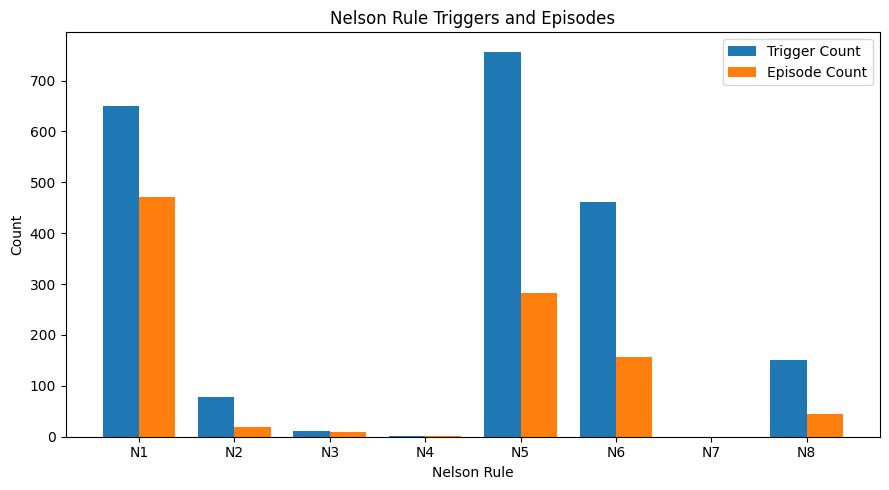

In [19]:
x = np.arange(len(nelson_totals))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    x - width / 2,
    nelson_totals["TRIGGER_COUNT"],
    width,
    label="Trigger Count"
)

ax.bar(
    x + width / 2,
    nelson_totals["EPISODE_COUNT"],
    width,
    label="Episode Count"
)

ax.set_xticks(x)
ax.set_xticklabels(nelson_totals["RULE"])

ax.set_title("Nelson Rule Triggers and Episodes")
ax.set_xlabel("Nelson Rule")
ax.set_ylabel("Count")
ax.legend()

plt.tight_layout()

save_figure(
    fig,
    "03_nelson_rule_summary.png"
)

plt.show()

## 3.1 Representative X̄ Chart with Nelson Rules

A representative Machine–CTQ stream is selected to show how the SPC analysis is applied.

The X̄ chart is displayed using standardized deviation rather than the original measurement values.

This protects confidential company specifications while retaining the statistical interpretation.

Nelson Rule signals are marked directly on the corresponding SPC events.

In [21]:
# ============================================================
# SELECT REPRESENTATIVE MACHINE–CTQ STREAM
# ============================================================

candidate = (
    spc
    .groupby(["MACH_NO", "CTQ"])
    .agg(
        EVENTS=("MACH_NO", "size"),
        NELSON_SIGNALS=("NELSON_ANY", "sum")
    )
    .reset_index()
    .sort_values(
        ["NELSON_SIGNALS", "EVENTS"],
        ascending=False
    )
)

display(candidate.head(10))

selected_machine = candidate.iloc[0]["MACH_NO"]
selected_ctq = candidate.iloc[0]["CTQ"]

example = spc[
    (spc["MACH_NO"] == selected_machine)
    &
    (spc["CTQ"] == selected_ctq)
].copy()

# ------------------------------------------------------------
# Find the correct production-order column automatically
# ------------------------------------------------------------

possible_order_columns = [
    "EVENT_DATE",
    "DATE",
    "DATETIME",
    "PROD_DATE",
    "PRODUCTION_DATE",
    "EVENT_TIME",
    "EVENT_INDEX",
    "SEQUENCE"
]

order_column = None

for column in possible_order_columns:
    if column in example.columns:
        order_column = column
        break

if order_column is not None:
    example = (
        example
        .sort_values(order_column)
        .reset_index(drop=True)
    )

    print("Sorted using:", order_column)

else:
    # Keep existing dataframe order if no date/sequence column exists
    example = example.reset_index(drop=True)

    print(
        "No explicit date/sequence column found. "
        "Existing production order is retained."
    )

print(
    "Representative stream:",
    selected_machine,
    "/",
    selected_ctq
)

print("Events in selected stream:", len(example))

display(example.head())

,MACH_NO,CTQ,EVENTS,NELSON_SIGNALS
37,WB13,SP,207,126
40,WB14,SP,202,92
36,WB13,BS,205,89
46,WB16,SP,146,83
6,WB03,BS,121,74
10,WB04,SP,139,73
45,WB16,BS,156,71
1,WB01,SP,152,67
0,WB01,BS,160,59
16,WB06,SP,88,58


No explicit date/sequence column found. Existing production order is retained.
Representative stream: WB13 / SP
Events in selected stream: 207


,EVENT_ID,CTQ,TID,LOT_ID,DEVICE,PACKAGE,MACH_NO,WIRE_TYPE,WIRE_DIAMETER,DATE_TIME,...,CONTROL_LIMIT_VIOLATION,SPEC_VIOLATION,PROCESS_STATE,CPL,CPU,CPK,CAPABILITY_TYPE,CAPABILITY_VALUE,WITHIN_SIGMA,BASELINE_STATUS
0,EVT0000002,SP,REC000002,LOT000001,REDACTED,PACKAGE_A,WB13,WIRE_TYPE_A,NaN,2020-01-01 00:06:08,...,True,False,ABNORMAL,2.643156,NaN,NaN,CPL,2.643156,0.557753,REVIEW
1,EVT0000008,SP,REC000008,LOT000002,REDACTED,PACKAGE_A,WB13,WIRE_TYPE_A,NaN,2020-02-01 16:20:05,...,False,False,NORMAL,2.643156,NaN,NaN,CPL,2.643156,0.557753,REVIEW
2,EVT0000010,SP,REC000010,LOT000004,REDACTED,PACKAGE_A,WB13,WIRE_TYPE_A,NaN,2020-02-03 04:07:40,...,False,False,WARNING,2.643156,NaN,NaN,CPL,2.643156,0.557753,REVIEW
3,EVT0000014,SP,REC000014,LOT000005,REDACTED,PACKAGE_A,WB13,WIRE_TYPE_A,NaN,2020-02-20 13:43:01,...,True,False,ABNORMAL,2.643156,NaN,NaN,CPL,2.643156,0.557753,REVIEW
4,EVT0000019,SP,REC000019,LOT000007,REDACTED,PACKAGE_A,WB13,WIRE_TYPE_A,NaN,2020-06-23 22:56:53,...,False,False,NORMAL,2.643156,NaN,NaN,CPL,2.643156,0.557753,REVIEW


Saved: C:\Users\User\src\WirebondingSPC\outputs\notebook_evidence\03_representative_xbar_nelson.png


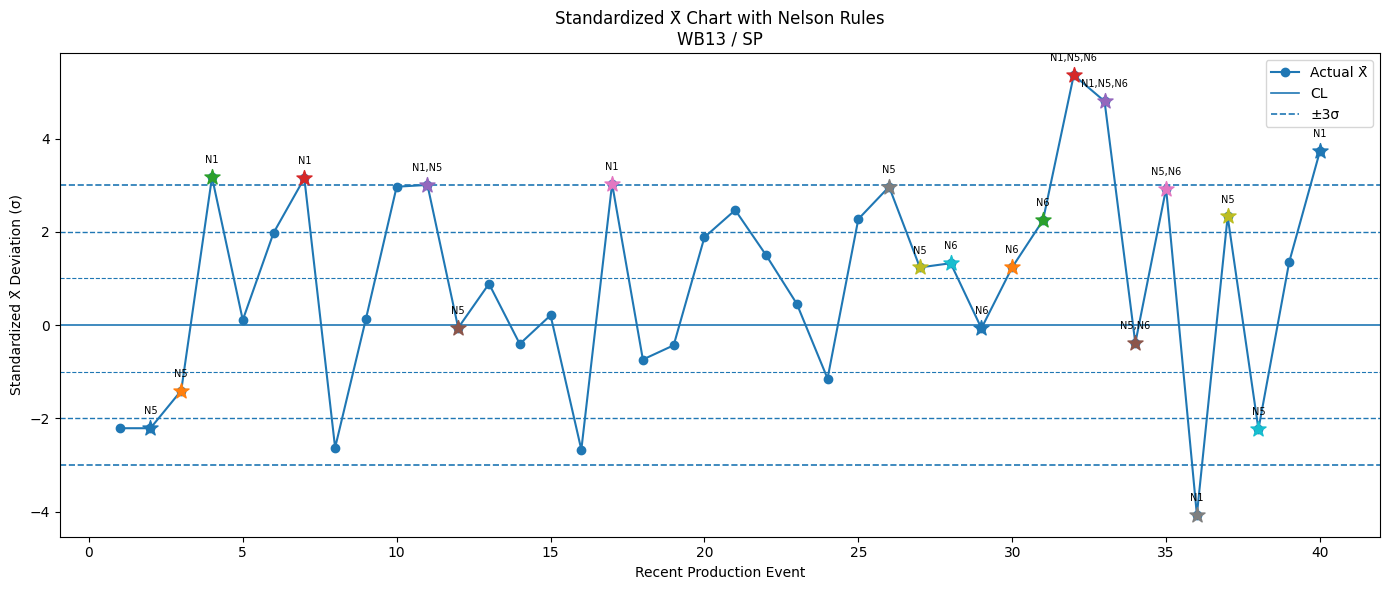

In [22]:
recent = (
    example
    .tail(40)
    .copy()
    .reset_index(drop=True)
)

recent["EVENT_NO"] = np.arange(1, len(recent) + 1)

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    recent["EVENT_NO"],
    recent["STANDARDIZED_DEVIATION"],
    marker="o",
    linewidth=1.5,
    label="Actual X̄"
)

ax.axhline(0, linewidth=1.2, label="CL")

ax.axhline(1, linestyle="--", linewidth=0.8)
ax.axhline(-1, linestyle="--", linewidth=0.8)

ax.axhline(2, linestyle="--", linewidth=1)
ax.axhline(-2, linestyle="--", linewidth=1)

ax.axhline(3, linestyle="--", linewidth=1.2, label="±3σ")
ax.axhline(-3, linestyle="--", linewidth=1.2)

rule_cols = [f"N{i}" for i in range(1, 9)]

for _, row in recent.iterrows():

    triggered = []

    for rule in rule_cols:

        if (
            rule in recent.columns
            and bool(row.get(rule, False))
        ):
            triggered.append(rule)

    if triggered:

        ax.scatter(
            row["EVENT_NO"],
            row["STANDARDIZED_DEVIATION"],
            marker="*",
            s=130,
            zorder=5
        )

        ax.annotate(
            ",".join(triggered),
            (
                row["EVENT_NO"],
                row["STANDARDIZED_DEVIATION"]
            ),
            xytext=(0, 10),
            textcoords="offset points",
            ha="center",
            fontsize=7
        )

ax.set_title(
    f"Standardized X̄ Chart with Nelson Rules\n"
    f"{selected_machine} / {selected_ctq}"
)

ax.set_xlabel("Recent Production Event")
ax.set_ylabel("Standardized X̄ Deviation (σ)")
ax.legend()

plt.tight_layout()

save_figure(
    fig,
    "03_representative_xbar_nelson.png"
)

plt.show()

## 3.2 Normalized R Chart

The R chart is used to monitor variation within each five-piece subgroup.

The range is normalized relative to the historical reference so that actual company measurement values are not disclosed.

Saved: C:\Users\User\src\WirebondingSPC\outputs\notebook_evidence\03_representative_r_chart.png


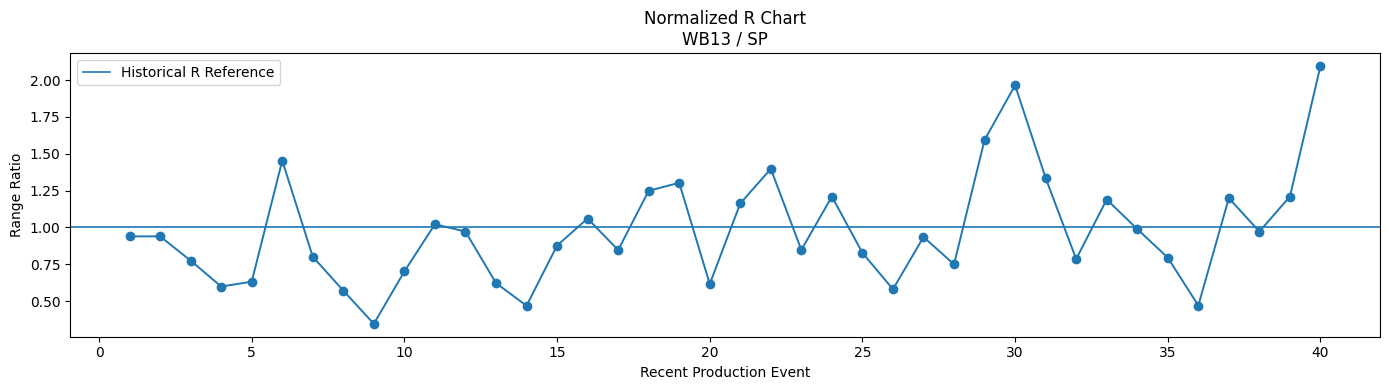

In [23]:
fig, ax = plt.subplots(figsize=(14, 4))

ax.plot(
    recent["EVENT_NO"],
    recent["RANGE_RATIO"],
    marker="o",
    linewidth=1.4
)

ax.axhline(
    1,
    linewidth=1.2,
    label="Historical R Reference"
)

ax.set_title(
    f"Normalized R Chart\n"
    f"{selected_machine} / {selected_ctq}"
)

ax.set_xlabel("Recent Production Event")
ax.set_ylabel("Range Ratio")

ax.legend()

plt.tight_layout()

save_figure(
    fig,
    "03_representative_r_chart.png"
)

plt.show()

## 3.3 Process-State Distribution

Each eligible SPC event is assigned one process state:

- Normal
- Warning
- Abnormal

Warning represents Nelson Rules N2 to N8 without an Abnormal condition.

Abnormal represents Nelson Rule N1, a control-limit violation or an applicable specification-limit violation.

These classes are later used as the MLP prediction target.

In [24]:
state_distribution = (
    spc.loc[
        spc["SPC_AVAILABLE"],
        "PROCESS_STATE"
    ]
    .value_counts()
    .rename_axis("PROCESS_STATE")
    .reset_index(name="EVENTS")
)

state_distribution["PERCENT"] = (
    state_distribution["EVENTS"]
    /
    state_distribution["EVENTS"].sum()
    *
    100
)

display(state_distribution)

,PROCESS_STATE,EVENTS,PERCENT
0,NORMAL,1626,55.118644
1,ABNORMAL,706,23.932203
2,WARNING,618,20.949153


Saved: C:\Users\User\src\WirebondingSPC\outputs\notebook_evidence\03_process_state_distribution.png


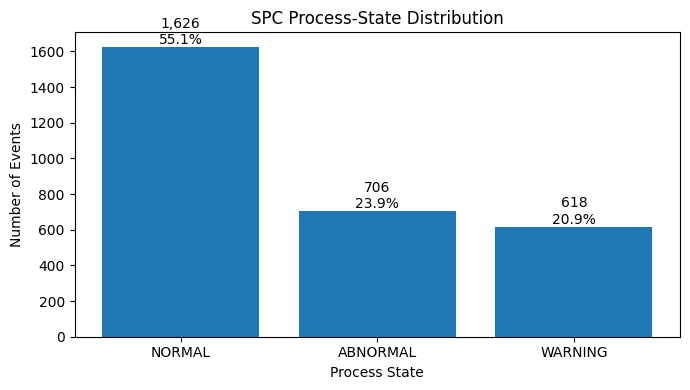

In [25]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.bar(
    state_distribution["PROCESS_STATE"],
    state_distribution["EVENTS"]
)

ax.set_title("SPC Process-State Distribution")
ax.set_xlabel("Process State")
ax.set_ylabel("Number of Events")

for i, row in state_distribution.iterrows():

    ax.text(
        i,
        row["EVENTS"],
        f'{int(row["EVENTS"]):,}\n'
        f'{row["PERCENT"]:.1f}%',
        ha="center",
        va="bottom"
    )

plt.tight_layout()

save_figure(
    fig,
    "03_process_state_distribution.png"
)

plt.show()

## 3.4 Process Capability Analysis

Capability indices provide supporting information about the relationship between process performance and the available specification limits.

The capability result is reviewed together with SPC stability and is not used alone to determine process condition.

In [26]:
display(capability.head(30))

,SPEC_KEY,CAPABILITY_EVENTS,CAPABILITY_MEAN,WITHIN_SIGMA,LSL,USL,CPL,CPU,CPK,CAPABILITY_TYPE,CAPABILITY_VALUE,MACH_NO,CTQ,REFERENCE_END
0,20.0/,111,39.367811,2.068617,20.0,NaN,3.120895,NaN,NaN,CPL,3.120895,WB01,BS,2020-12-15 08:07:20
1,2.0/,102,6.526196,0.591249,2.0,NaN,2.551771,NaN,NaN,CPL,2.551771,WB01,SP,2020-12-15 08:07:20
2,2.5/,2,6.541000,0.730009,2.5,NaN,1.845184,NaN,NaN,CPL,1.845184,WB01,SP,2020-12-15 08:07:20
3,3.5/,51,9.413137,0.596766,3.5,NaN,3.302877,NaN,NaN,CPL,3.302877,WB01,WP,2020-12-15 08:07:20
4,20.0/,61,40.135416,1.490704,20.0,NaN,4.502441,NaN,NaN,CPL,4.502441,WB03,BS,2020-12-15 08:07:20
5,2.0/,59,6.518085,0.568853,2.0,NaN,2.647481,NaN,NaN,CPL,2.647481,WB03,SP,2020-12-15 08:07:20
6,3.5/,1,5.830400,0.368874,3.5,NaN,2.105870,NaN,NaN,CPL,2.105870,WB03,SP,2020-12-15 08:07:20
7,3.5/,28,8.686229,0.500676,3.5,NaN,3.452820,NaN,NaN,CPL,3.452820,WB03,WP,2020-12-15 08:07:20
8,20.0/,83,40.695178,3.631085,20.0,NaN,1.899816,NaN,NaN,CPL,1.899816,WB04,BS,2020-12-15 08:07:20
9,2.0/,82,6.588115,0.577155,2.0,NaN,2.649844,NaN,NaN,CPL,2.649844,WB04,SP,2020-12-15 08:07:20


Saved: C:\Users\User\src\WirebondingSPC\outputs\notebook_evidence\03_capability_by_stream.png


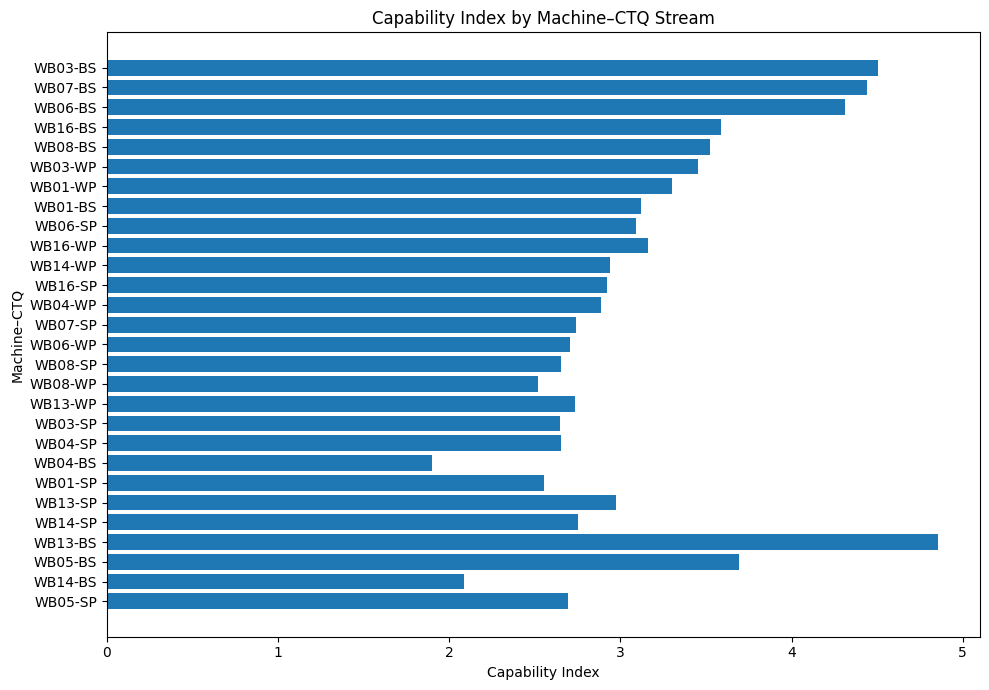

In [27]:
cap_plot = capability.copy()

if "CAPABILITY_VALUE" in cap_plot.columns:

    cap_plot = (
        cap_plot
        .dropna(subset=["CAPABILITY_VALUE"])
        .copy()
    )

    cap_plot["STREAM"] = (
        cap_plot["MACH_NO"].astype(str)
        + "-"
        + cap_plot["CTQ"].astype(str)
    )

    cap_plot = (
        cap_plot
        .sort_values("CAPABILITY_VALUE")
    )

    fig, ax = plt.subplots(figsize=(10, 7))

    ax.barh(
        cap_plot["STREAM"],
        cap_plot["CAPABILITY_VALUE"]
    )

    ax.set_title(
        "Capability Index by Machine–CTQ Stream"
    )

    ax.set_xlabel("Capability Index")
    ax.set_ylabel("Machine–CTQ")

    plt.tight_layout()

    save_figure(
        fig,
        "03_capability_by_stream.png"
    )

    plt.show()

## 3.5 Break-Mode Analysis

Break-mode information is reviewed as supporting wire-bond engineering evidence.

The break-mode distribution helps identify whether one mode becomes dominant or whether the mechanical failure pattern changes.

Break-mode information is not treated as a confirmed physical root cause by itself.

In [28]:
mode_cols = [
    col
    for col in [
        "MODE_A_COUNT",
        "MODE_B_COUNT",
        "MODE_C_COUNT",
        "MODE_D_COUNT",
        "MODE_E_COUNT"
    ]
    if col in spc.columns
]

break_mode_total = pd.DataFrame(
    {
        "MODE": [
            col
            .replace("MODE_", "")
            .replace("_COUNT", "")
            for col in mode_cols
        ],
        "COUNT": [
            spc[col].sum()
            for col in mode_cols
        ]
    }
)

display(break_mode_total)

,MODE,COUNT
0,A,6956
1,B,3035
2,C,31
3,D,6708
4,E,0


Saved: C:\Users\User\src\WirebondingSPC\outputs\notebook_evidence\03_break_mode_distribution.png


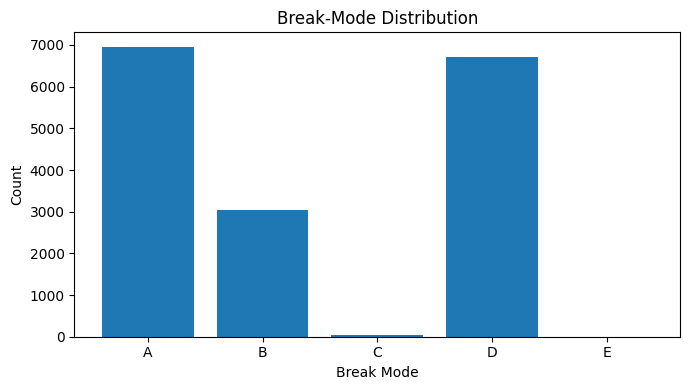

In [29]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.bar(
    break_mode_total["MODE"],
    break_mode_total["COUNT"]
)

ax.set_title("Break-Mode Distribution")
ax.set_xlabel("Break Mode")
ax.set_ylabel("Count")

plt.tight_layout()

save_figure(
    fig,
    "03_break_mode_distribution.png"
)

plt.show()

# 4. Feature Engineering

The SPC results are converted into predictive-model features.

The features represent current process condition and recent process history.

The main feature groups include:

- mean, standard deviation, range and coefficient of variation;
- standardized SPC deviation;
- range ratio;
- process capability;
- Nelson Rule indicators N1 to N8;
- Nelson Rule counts;
- break-mode counts;
- lag values;
- rolling averages;
- previous Warning and Abnormal rates;
- previous process-state information;
- anonymized Machine ID and CTQ.

Device information is not used as an MLP input.

In [30]:
features = build_features(spc)

print("Feature dataset shape:", features.shape)

display(features.head())

Feature dataset shape: (2950, 113)


,EVENT_ID,CTQ,TID,LOT_ID,DEVICE,PACKAGE,MACH_NO,WIRE_TYPE,WIRE_DIAMETER,DATE_TIME,...,PREVIOUS_ABNORMAL_RATE_5,PREVIOUS_NELSON_RATE_5,PREVIOUS_NELSON_RATE_10,PREVIOUS_NELSON_EPISODE_RATE_10,EVENTS_SINCE_PREVIOUS_NELSON,HOURS_SINCE_PREVIOUS,CURRENT_STATE_RANK,TARGET_FUTURE_STATE,TARGET_FUTURE_TIME,TARGET_FUTURE_EVENT_ID
0,EVT0000001,BS,REC000001,LOT000001,REDACTED,PACKAGE_A,WB13,WIRE_TYPE_A,NaN,2020-01-01 00:00:00,...,NaN,NaN,NaN,NaN,NaN,NaN,2.0,WARNING,2020-06-23 22:50:46,EVT0000017
1,EVT0000002,SP,REC000002,LOT000001,REDACTED,PACKAGE_A,WB13,WIRE_TYPE_A,NaN,2020-01-01 00:06:08,...,NaN,NaN,NaN,NaN,NaN,NaN,2.0,WARNING,2020-06-27 01:53:12,EVT0000025
2,EVT0000003,WP,REC000003,LOT000001,REDACTED,PACKAGE_A,WB13,WIRE_TYPE_A,NaN,2020-01-01 00:08:19,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NORMAL,2020-07-01 04:33:57,EVT0000035
3,EVT0000004,BS,REC000004,LOT000002,REDACTED,PACKAGE_A,WB13,WIRE_TYPE_A,NaN,2020-02-01 03:50:13,...,1.0,1.0,1.0,1.0,1.0,747.836944,2.0,NORMAL,2020-06-27 01:51:42,EVT0000024
4,EVT0000005,WP,REC000005,LOT000002,REDACTED,PACKAGE_A,WB13,WIRE_TYPE_A,NaN,2020-02-01 03:54:39,...,0.0,0.0,0.0,0.0,NaN,747.772222,0.0,ABNORMAL,2020-07-01 04:43:24,EVT0000039


In [31]:
feature_list = pd.DataFrame(
    {
        "FEATURE": features.columns
    }
)

display(feature_list)

,FEATURE
0,EVENT_ID
1,CTQ
2,TID
3,LOT_ID
4,DEVICE
...,...
108,HOURS_SINCE_PREVIOUS
109,CURRENT_STATE_RANK
110,TARGET_FUTURE_STATE
111,TARGET_FUTURE_TIME


# 5. Training, Validation and Test Dataset

The predictive dataset is separated according to production sequence.

Random splitting is avoided because later observations should not appear in earlier model-development data.

The initial split is approximately:

- 60% training;
- 20% validation;
- 20% testing.

Because the target is the fifth subsequent event, observations near dataset boundaries are removed when their target falls into the next dataset.

In [32]:
(
    labelled,
    split_meta,
    split_summary,
    split_class_summary
) = chronological_split(
    features,
    split_meta
)

print("Dataset split")

display(split_summary)

print("\nClass distribution by split")

display(split_class_summary)

Dataset split


,SPLIT,ROWS,PERCENT_OF_LABELLED
0,TRAIN,1810,64.412811
1,VALIDATION,407,14.483986
2,TEST,341,12.135231
3,PURGED,252,8.967972



Class distribution by split


,SPLIT,STATE,ROWS
0,TRAIN,NORMAL,963
1,TRAIN,WARNING,400
2,TRAIN,ABNORMAL,447
3,VALIDATION,NORMAL,250
4,VALIDATION,WARNING,74
5,VALIDATION,ABNORMAL,83
6,TEST,NORMAL,193
7,TEST,WARNING,66
8,TEST,ABNORMAL,82


Saved: C:\Users\User\src\WirebondingSPC\outputs\notebook_evidence\05_dataset_split.png


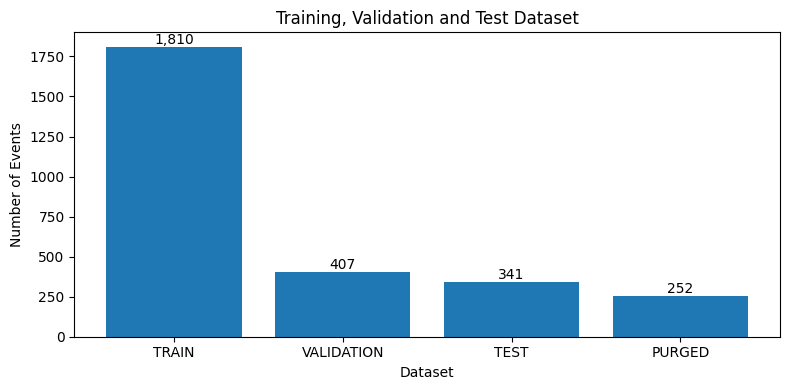

In [33]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(
    split_summary["SPLIT"],
    split_summary["ROWS"]
)

ax.set_title("Training, Validation and Test Dataset")
ax.set_xlabel("Dataset")
ax.set_ylabel("Number of Events")

for i, row in split_summary.iterrows():

    ax.text(
        i,
        row["ROWS"],
        f'{int(row["ROWS"]):,}',
        ha="center",
        va="bottom"
    )

plt.tight_layout()

save_figure(
    fig,
    "05_dataset_split.png"
)

plt.show()

# 6. ARIMA Forecasting

ARIMA is the time-series forecasting branch.

It is applied independently to eligible Machine–CTQ streams.

Several candidate ARIMA orders are tested using validation data.

The model with the lowest fifth-event validation RMSE is selected.

Final performance is evaluated using the untouched test data and compared with a naïve fifth-event forecast.

In [34]:
arima = train_arima(
    features,
    split_meta
)

print("ARIMA Model Selection")
display(arima.selection.head(30))

print("\nARIMA Test Metrics")
display(arima.metrics.head(30))

ARIMA Model Selection


,MACH_NO,CTQ,ORDER,VALIDATION_RMSE,VALIDATION_N,STATUS
0,WB01,BS,"(1, 0, 0)",1.840265,17,Candidate
1,WB01,BS,"(1, 1, 0)",2.042323,17,Candidate
2,WB01,BS,"(0, 1, 1)",2.167174,17,Candidate
3,WB01,BS,"(1, 1, 1)",2.182634,17,Candidate
4,WB01,SP,"(1, 0, 0)",2.044505,18,Candidate
5,WB01,SP,"(1, 1, 0)",2.754256,18,Candidate
6,WB01,SP,"(0, 1, 1)",2.154947,18,Candidate
7,WB01,SP,"(1, 1, 1)",2.158443,18,Candidate
8,WB01,WP,"(1, 0, 0)",5.396554,2,Candidate
9,WB01,WP,"(1, 1, 0)",4.279353,2,Candidate



ARIMA Test Metrics


,MACH_NO,CTQ,ORDER,TEST_N,H5_MAE,H5_MSE,H5_RMSE,NAIVE_H5_RMSE,H5_INTERVAL_COVERAGE_%,EVIDENCE_LEVEL
0,WB01,BS,"(1, 0, 0)",22,2.571749,10.134056,3.183403,3.528600,86.363636,ADEQUATE
1,WB01,SP,"(1, 0, 0)",20,1.896272,6.156171,2.481163,2.885106,95.000000,ADEQUATE
2,WB01,WP,"(1, 1, 0)",6,2.088706,5.232624,2.287493,2.104793,100.000000,LIMITED
3,WB03,BS,"(1, 0, 0)",24,1.934634,7.751128,2.784085,3.551857,95.833333,ADEQUATE
4,WB03,SP,"(0, 1, 1)",21,2.175668,6.924409,2.631427,3.646102,95.238095,ADEQUATE
5,WB03,WP,"(1, 1, 1)",8,2.116124,8.448044,2.906552,4.099207,75.000000,LIMITED
6,WB04,BS,"(1, 1, 1)",27,1.308460,3.079016,1.754712,2.514864,100.000000,ADEQUATE
7,WB04,SP,"(0, 1, 1)",28,2.333636,8.595763,2.931853,3.675403,92.857143,ADEQUATE
8,WB04,WP,"(1, 1, 0)",7,3.140551,12.880649,3.588962,3.936727,100.000000,LIMITED
9,WB06,BS,"(1, 0, 0)",10,1.847250,6.974350,2.640899,2.923672,100.000000,ADEQUATE


Saved: C:\Users\User\src\WirebondingSPC\outputs\notebook_evidence\06_arima_rmse_vs_naive.png


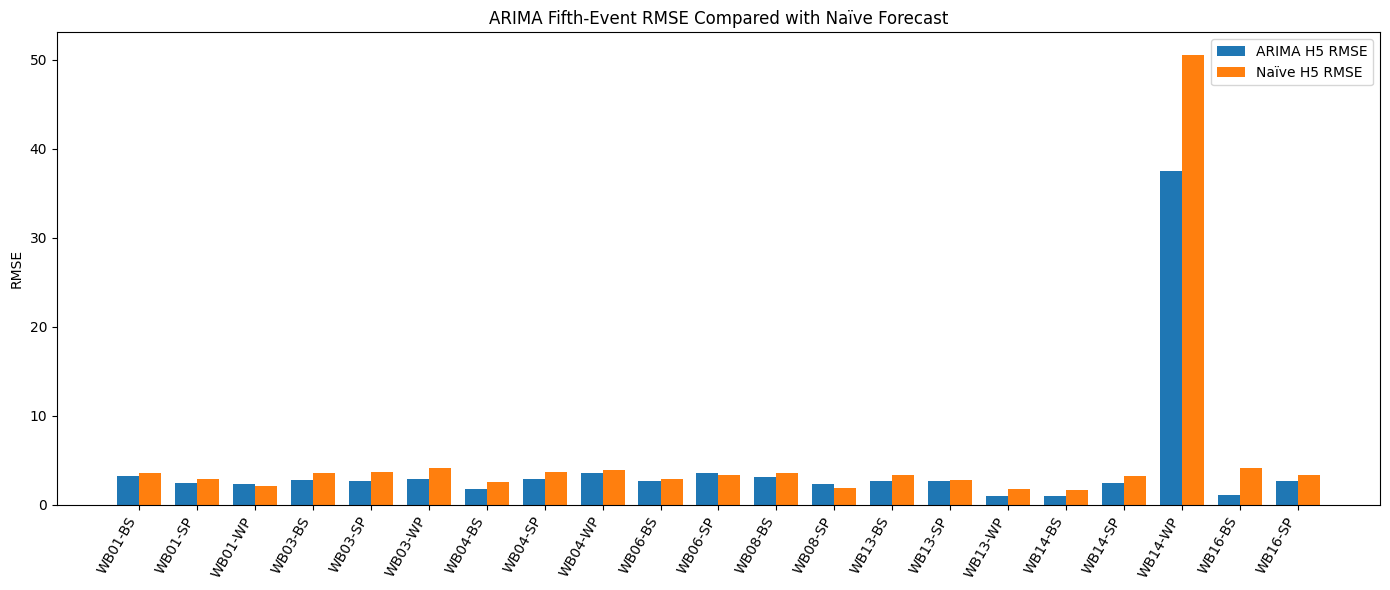

In [35]:
arima_compare = arima.metrics.copy()

arima_compare["STREAM"] = (
    arima_compare["MACH_NO"].astype(str)
    + "-"
    + arima_compare["CTQ"].astype(str)
)

x = np.arange(len(arima_compare))
width = 0.38

fig, ax = plt.subplots(figsize=(14, 6))

ax.bar(
    x - width / 2,
    arima_compare["H5_RMSE"],
    width,
    label="ARIMA H5 RMSE"
)

ax.bar(
    x + width / 2,
    arima_compare["NAIVE_H5_RMSE"],
    width,
    label="Naïve H5 RMSE"
)

ax.set_xticks(x)

ax.set_xticklabels(
    arima_compare["STREAM"],
    rotation=60,
    ha="right"
)

ax.set_title(
    "ARIMA Fifth-Event RMSE Compared with Naïve Forecast"
)

ax.set_ylabel("RMSE")
ax.legend()

plt.tight_layout()

save_figure(
    fig,
    "06_arima_rmse_vs_naive.png"
)

plt.show()

In [36]:
display(
    arima.forecast.head(30)
)

,MACH_NO,CTQ,HORIZON_EVENT,FORECAST_Z,LOWER_95,UPPER_95,ARIMA_ORDER,LAST_OBSERVED_TIME
0,WB01,BS,1,0.264216,-4.573805,5.102237,"(1, 0, 0)",2021-04-13 22:48:04
1,WB01,BS,2,0.148581,-4.714478,5.011640,"(1, 0, 0)",2021-04-13 22:48:04
2,WB01,BS,3,0.136801,-4.726517,5.000120,"(1, 0, 0)",2021-04-13 22:48:04
3,WB01,BS,4,0.135601,-4.727720,4.998922,"(1, 0, 0)",2021-04-13 22:48:04
4,WB01,BS,5,0.135479,-4.727842,4.998800,"(1, 0, 0)",2021-04-13 22:48:04
5,WB01,SP,1,-0.027126,-4.963154,4.908902,"(1, 0, 0)",2021-04-13 22:49:27
6,WB01,SP,2,-0.035803,-4.987702,4.916097,"(1, 0, 0)",2021-04-13 22:49:27
7,WB01,SP,3,-0.036499,-4.988501,4.915502,"(1, 0, 0)",2021-04-13 22:49:27
8,WB01,SP,4,-0.036555,-4.988557,4.915447,"(1, 0, 0)",2021-04-13 22:49:27
9,WB01,SP,5,-0.036559,-4.988562,4.915443,"(1, 0, 0)",2021-04-13 22:49:27


# 7. MLP Classification

The MLP is the classification branch.

It uses the engineered SPC features to predict whether the fifth subsequent event will be:

- Normal
- Warning
- Abnormal

Candidate MLP structures are compared using validation Macro F1-score.

Oversampling is applied only to model-development data.

The final selected model is evaluated using the untouched test dataset.

In [37]:
mlp = train_mlp(
    features,
    labelled,
    MODEL_OUTPUT_DIR
)

print("MLP Validation Results")
display(mlp.validation)

print("\nMLP Test Metrics")
display(mlp.metrics)

MLP Validation Results


,HIDDEN_LAYERS,ALPHA,VALIDATION_MACRO_F1
0,"(16,)",0.001,0.347857
2,"(32, 16)",0.010,0.335460
1,"(32, 16)",0.001,0.307737



MLP Test Metrics


,MODEL,TEST_N,SELECTED_HIDDEN_LAYERS,SELECTED_ALPHA,ACCURACY,BALANCED_ACCURACY,MACRO_PRECISION,MACRO_RECALL,MACRO_F1,PRECISION_NORMAL,PRECISION_WARNING,PRECISION_ABNORMAL,RECALL_NORMAL,RECALL_WARNING,RECALL_ABNORMAL,F1_NORMAL,F1_WARNING,F1_ABNORMAL,ROC_AUC_OVR_MACRO
0,MLP,341,"(16,)",0.001,0.395894,0.359429,0.36259,0.359429,0.352591,0.631206,0.211111,0.245455,0.46114,0.287879,0.329268,0.532934,0.24359,0.28125,0.532999


In [39]:
print("MLP validation columns:")
print(mlp.validation.columns.tolist())

display(mlp.validation)

MLP validation columns:
['HIDDEN_LAYERS', 'ALPHA', 'VALIDATION_MACRO_F1']


,HIDDEN_LAYERS,ALPHA,VALIDATION_MACRO_F1
0,"(16,)",0.001,0.347857
2,"(32, 16)",0.010,0.335460
1,"(32, 16)",0.001,0.307737


Saved: C:\Users\User\src\WirebondingSPC\outputs\notebook_evidence\07_mlp_validation.png


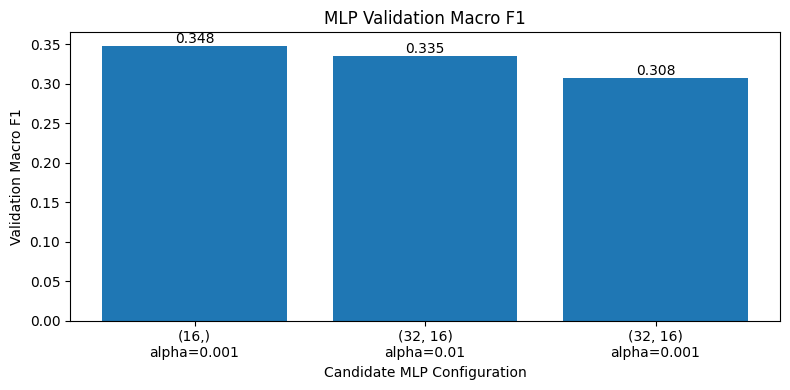

In [40]:
validation_plot = mlp.validation.copy()

validation_plot["MODEL"] = (
    validation_plot["HIDDEN_LAYERS"].astype(str)
    + "\nalpha="
    + validation_plot["ALPHA"].astype(str)
)

fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(
    validation_plot["MODEL"],
    validation_plot["VALIDATION_MACRO_F1"]
)

ax.set_title("MLP Validation Macro F1")
ax.set_xlabel("Candidate MLP Configuration")
ax.set_ylabel("Validation Macro F1")

for i, value in enumerate(validation_plot["VALIDATION_MACRO_F1"]):
    ax.text(
        i,
        value,
        f"{value:.3f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

save_figure(
    fig,
    "07_mlp_validation.png"
)

plt.show()

In [41]:
print("MLP Confusion Matrix")
display(mlp.confusion)

print("\nMLP Class-Level Performance")
display(mlp.class_report)

MLP Confusion Matrix


,ACTUAL_STATE,PREDICTED_STATE,COUNT
0,NORMAL,NORMAL,89
1,WARNING,NORMAL,22
2,ABNORMAL,NORMAL,30
3,NORMAL,WARNING,46
4,WARNING,WARNING,19
5,ABNORMAL,WARNING,25
6,NORMAL,ABNORMAL,58
7,WARNING,ABNORMAL,25
8,ABNORMAL,ABNORMAL,27



MLP Class-Level Performance


,STATE,PRECISION,RECALL,F1,SUPPORT
0,NORMAL,0.631206,0.461140,0.532934,193
1,WARNING,0.211111,0.287879,0.243590,66
2,ABNORMAL,0.245455,0.329268,0.281250,82


In [43]:
print("Confusion matrix columns:")
print(mlp.confusion.columns.tolist())

display(mlp.confusion)

print("\nData types:")
print(mlp.confusion.dtypes)


Confusion matrix columns:
['ACTUAL_STATE', 'PREDICTED_STATE', 'COUNT']


,ACTUAL_STATE,PREDICTED_STATE,COUNT
0,NORMAL,NORMAL,89
1,WARNING,NORMAL,22
2,ABNORMAL,NORMAL,30
3,NORMAL,WARNING,46
4,WARNING,WARNING,19
5,ABNORMAL,WARNING,25
6,NORMAL,ABNORMAL,58
7,WARNING,ABNORMAL,25
8,ABNORMAL,ABNORMAL,27



Data types:
ACTUAL_STATE       object
PREDICTED_STATE    object
COUNT               int64
dtype: object


,ACTUAL_STATE,PREDICTED_STATE,COUNT
0,NORMAL,NORMAL,89
1,WARNING,NORMAL,22
2,ABNORMAL,NORMAL,30
3,NORMAL,WARNING,46
4,WARNING,WARNING,19
5,ABNORMAL,WARNING,25
6,NORMAL,ABNORMAL,58
7,WARNING,ABNORMAL,25
8,ABNORMAL,ABNORMAL,27


Matrix shape: (9, 2)
Matrix dtype: float64
Saved: C:\Users\User\src\WirebondingSPC\outputs\notebook_evidence\07_mlp_confusion_matrix.png


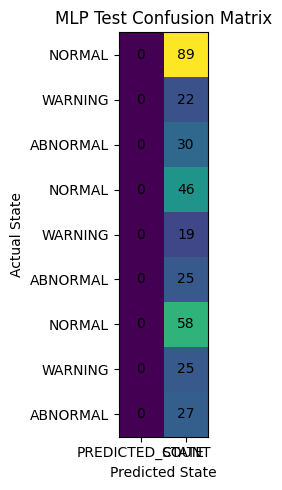

In [44]:
# ============================================================
# MLP CONFUSION MATRIX FIGURE
# ============================================================

conf = mlp.confusion.copy()

display(conf)

# ------------------------------------------------------------
# Detect label column
# ------------------------------------------------------------

label_col = conf.columns[0]

row_labels = conf[label_col].astype(str)

# Keep only remaining columns as matrix values
matrix = conf.drop(columns=[label_col]).copy()

# Convert every matrix column to numeric
for col in matrix.columns:
    matrix[col] = pd.to_numeric(
        matrix[col],
        errors="coerce"
    )

# Replace any unexpected missing values with 0
matrix = matrix.fillna(0)

# Convert to numeric NumPy array
matrix_values = matrix.to_numpy(dtype=float)

print("Matrix shape:", matrix_values.shape)
print("Matrix dtype:", matrix_values.dtype)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(6, 5))

im = ax.imshow(
    matrix_values
)

ax.set_xticks(
    np.arange(len(matrix.columns))
)

ax.set_xticklabels(
    matrix.columns
)

ax.set_yticks(
    np.arange(len(row_labels))
)

ax.set_yticklabels(
    row_labels
)

ax.set_xlabel("Predicted State")
ax.set_ylabel("Actual State")
ax.set_title("MLP Test Confusion Matrix")

# Add count inside each cell
for i in range(matrix_values.shape[0]):
    for j in range(matrix_values.shape[1]):

        ax.text(
            j,
            i,
            f"{int(matrix_values[i, j])}",
            ha="center",
            va="center"
        )

plt.tight_layout()

save_figure(
    fig,
    "07_mlp_confusion_matrix.png"
)

plt.show()

# 8. Fork-Based Hybrid Evaluation

ARIMA and MLP remain independent predictive branches.

ARIMA provides future numerical SPC-trend information.

MLP provides future process-state classification.

Their outputs are combined only at the decision level.

For fair comparison, SPC Persistence, ARIMA, MLP and Hybrid are evaluated using the same common test observations.

In [45]:
(
    comparison,
    hybrid_predictions
) = evaluate_fork(
    mlp.predictions,
    arima.predictions
)

display(comparison)

,MODEL,TEST_N,ACCURACY,BALANCED_ACCURACY,MACRO_PRECISION,MACRO_RECALL,MACRO_F1,PRECISION_NORMAL,PRECISION_WARNING,PRECISION_ABNORMAL,RECALL_NORMAL,RECALL_WARNING,RECALL_ABNORMAL,F1_NORMAL,F1_WARNING,F1_ABNORMAL,ROC_AUC_OVR_MACRO
0,SPC Persistence,305,0.475410,0.397700,0.399407,0.397700,0.397353,0.618497,0.257143,0.322581,0.640719,0.285714,0.266667,0.629412,0.270677,0.291971,NaN
1,ARIMA,305,0.557377,0.356552,0.455825,0.356552,0.291855,0.567474,0.300000,0.500000,0.982036,0.047619,0.040000,0.719298,0.082192,0.074074,NaN
2,MLP,305,0.403279,0.366030,0.368578,0.366030,0.361586,0.620155,0.227848,0.257732,0.479042,0.285714,0.333333,0.540541,0.253521,0.290698,NaN
3,Hybrid,305,0.406557,0.372076,0.374806,0.372076,0.366238,0.632000,0.215190,0.277228,0.473054,0.269841,0.373333,0.541096,0.239437,0.318182,NaN


Saved: C:\Users\User\src\WirebondingSPC\outputs\notebook_evidence\08_model_comparison.png


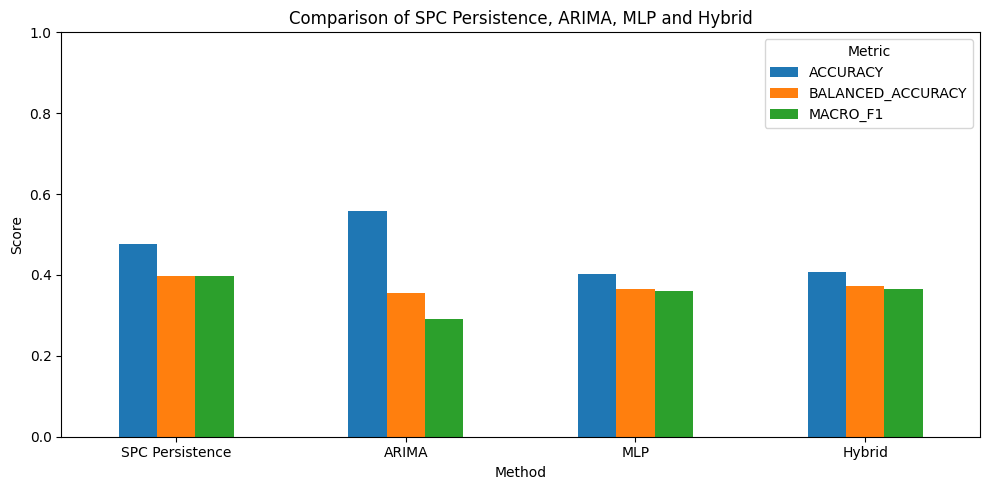

In [46]:
metrics_to_plot = [
    "ACCURACY",
    "BALANCED_ACCURACY",
    "MACRO_F1"
]

comparison_plot = (
    comparison
    .set_index("MODEL")[metrics_to_plot]
)

fig, ax = plt.subplots(figsize=(10, 5))

comparison_plot.plot(
    kind="bar",
    ax=ax
)

ax.set_title(
    "Comparison of SPC Persistence, ARIMA, MLP and Hybrid"
)

ax.set_xlabel("Method")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)

ax.tick_params(
    axis="x",
    rotation=0
)

ax.legend(title="Metric")

plt.tight_layout()

save_figure(
    fig,
    "08_model_comparison.png"
)

plt.show()

Saved: C:\Users\User\src\WirebondingSPC\outputs\notebook_evidence\08_abnormal_recall_comparison.png


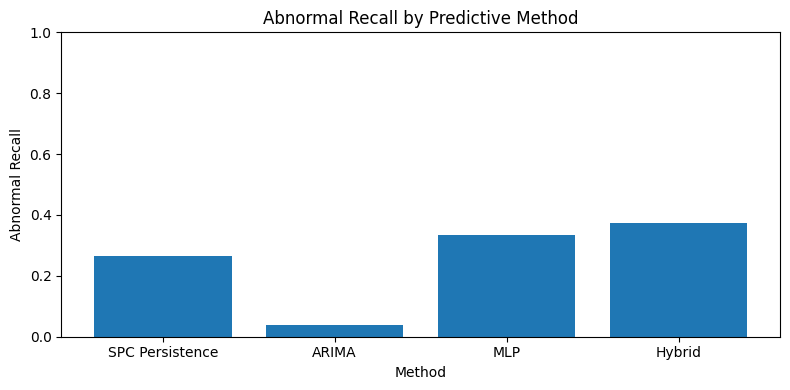

In [47]:
if "RECALL_ABNORMAL" in comparison.columns:

    fig, ax = plt.subplots(figsize=(8, 4))

    ax.bar(
        comparison["MODEL"],
        comparison["RECALL_ABNORMAL"]
    )

    ax.set_title(
        "Abnormal Recall by Predictive Method"
    )

    ax.set_xlabel("Method")
    ax.set_ylabel("Abnormal Recall")

    ax.set_ylim(0, 1)

    plt.tight_layout()

    save_figure(
        fig,
        "08_abnormal_recall_comparison.png"
    )

    plt.show()

# 9. Engineering Decision-Support Output

The final stage converts the current SPC condition and predictive outputs into engineering decision-support information.

The latest Machine–CTQ output contains:

- current SPC state;
- ARIMA fifth-event state;
- MLP fifth-event state;
- Hybrid future state;
- engineering action;
- engineering guidance.

The system is a support tool and does not automatically stop equipment or change bonding parameters.

In [48]:
latest_status = build_latest_status(
    features,
    mlp.latest,
    arima.latest
)

display(latest_status)

,MACH_NO,CTQ,LATEST_TIME,CURRENT_STATE,NELSON_RULE_COUNT,NELSON_ANY,NELSON_RULES_TRIGGERED,NELSON_EPISODES_STARTED,CAPABILITY_TYPE,CAPABILITY_VALUE,...,P_NORMAL,P_WARNING,P_ABNORMAL,ARIMA_PRED_STATE,FORECAST_H5_Z,HYBRID_DECISION,FUTURE_STATE,OVERALL_DECISION,DECISION_PRIORITY,ENGINEERING_GUIDANCE
0,WB01,BS,2021-04-13 22:48:04,NORMAL,0,False,,0,CPL,3.120895,...,0.228785,0.255110,0.516105,NORMAL,0.135479,ABNORMAL,ABNORMAL,ABNORMAL,HIGH,"Review recent SPC points, Nelson signals and b..."
1,WB01,SP,2021-04-13 22:49:27,NORMAL,0,False,,0,CPL,2.551771,...,0.479315,0.282954,0.237731,NORMAL,-0.036559,NORMAL,NORMAL,NORMAL,LOW,Continue routine SPC monitoring.
2,WB01,WP,2021-04-09 23:07:58,NORMAL,0,False,,0,CPL,3.302877,...,0.036191,0.240400,0.723409,NORMAL,-0.097985,ABNORMAL,ABNORMAL,ABNORMAL,HIGH,"Review recent SPC points, Nelson signals and b..."
3,WB03,BS,2021-04-13 22:43:40,WARNING,1,True,N8,1,CPL,4.502441,...,0.244630,0.134421,0.620949,NORMAL,0.130682,ABNORMAL,ABNORMAL,ABNORMAL,HIGH,"Review recent SPC points, Nelson signals and b..."
4,WB03,SP,2021-04-13 22:44:49,WARNING,1,True,N6,0,CPL,2.647481,...,0.655479,0.147065,0.197456,NORMAL,-0.850893,NORMAL,NORMAL,WARNING,MEDIUM,Review recent trend and lot history; continue ...
5,WB03,WP,2021-04-03 11:36:53,ABNORMAL,1,True,N1,0,CPL,3.452820,...,0.539298,0.217181,0.243521,NORMAL,-0.141739,NORMAL,NORMAL,ABNORMAL,HIGH,"Review recent SPC points, Nelson signals and b..."
6,WB04,BS,2021-04-14 10:45:50,NORMAL,0,False,,0,CPL,1.899816,...,0.562963,0.310599,0.126438,NORMAL,-0.156379,NORMAL,NORMAL,NORMAL,LOW,Continue routine SPC monitoring.
7,WB04,SP,2021-04-14 10:48:49,NORMAL,0,False,,0,CPL,2.649844,...,0.555832,0.320845,0.123324,NORMAL,-0.352453,NORMAL,NORMAL,NORMAL,LOW,Continue routine SPC monitoring.
8,WB04,WP,2021-04-14 10:50:00,WARNING,1,True,N5,1,CPL,2.887017,...,0.567895,0.407570,0.024534,WARNING,2.619253,WARNING,WARNING,WARNING,MEDIUM,Review recent trend and lot history; continue ...
9,WB05,BS,2020-11-20 00:09:13,NORMAL,0,False,,0,CPL,3.689813,...,0.558690,0.100238,0.341072,NORMAL,-0.067597,NORMAL,NORMAL,NORMAL,LOW,Continue routine SPC monitoring.


In [49]:
if "ENGINEERING_ACTION" in latest_status.columns:

    action_summary = (
        latest_status["ENGINEERING_ACTION"]
        .value_counts()
        .rename_axis("ACTION")
        .reset_index(name="COUNT")
    )

    display(action_summary)

    fig, ax = plt.subplots(figsize=(9, 4))

    ax.bar(
        action_summary["ACTION"],
        action_summary["COUNT"]
    )

    ax.set_title(
        "Engineering DSS Action Distribution"
    )

    ax.set_xlabel(
        "Engineering Action"
    )

    ax.set_ylabel(
        "Machine–CTQ Count"
    )

    ax.tick_params(
        axis="x",
        rotation=25
    )

    plt.tight_layout()

    save_figure(
        fig,
        "09_dss_action_distribution.png"
    )

    plt.show()

# 10. Save Final Analysis Tables

The final cell saves the main numerical results generated in this notebook.

These tables can be used as supporting evidence for Chapters 4 and 5 and for VIVA presentation.

In [51]:
# ============================================================
# SAVE ANALYSIS EVIDENCE TABLES
# ============================================================

EVIDENCE_DIR.mkdir(parents=True, exist_ok=True)

saved_files = []

def save_csv(df, filename):
    if df is not None and isinstance(df, pd.DataFrame):
        path = EVIDENCE_DIR / filename
        df.to_csv(path, index=False)
        saved_files.append(filename)
        print("Saved:", filename)
    else:
        print("Skipped:", filename)

save_csv(
    cleaning_audit,
    "01_cleaning_audit.csv"
)

save_csv(
    ctq_count,
    "01_cleaned_ctq_count.csv"
)

save_csv(
    selected_ctq,
    "02_selected_population_by_ctq.csv"
)

save_csv(
    machine_distribution,
    "02_machine_distribution.csv"
)

save_csv(
    nelson_totals,
    "03_nelson_rule_summary.csv"
)

save_csv(
    state_distribution,
    "03_process_state_distribution.csv"
)

save_csv(
    capability,
    "03_capability_results.csv"
)

save_csv(
    break_mode_total,
    "03_break_mode_distribution.csv"
)

save_csv(
    split_summary,
    "05_dataset_split.csv"
)

save_csv(
    split_class_summary,
    "05_split_class_distribution.csv"
)

save_csv(
    arima.metrics,
    "06_arima_test_metrics.csv"
)

save_csv(
    mlp.validation,
    "07_mlp_validation.csv"
)

save_csv(
    mlp.metrics,
    "07_mlp_test_metrics.csv"
)

save_csv(
    mlp.class_report,
    "07_mlp_class_performance.csv"
)

save_csv(
    comparison,
    "08_model_comparison.csv"
)

save_csv(
    latest_status,
    "09_latest_machine_status.csv"
)

print("\nAll available analysis evidence has been saved.")
print("Location:")
print(EVIDENCE_DIR)

print("\nFiles saved:")
for file in saved_files:
    print("-", file)

Saved: 01_cleaning_audit.csv
Saved: 01_cleaned_ctq_count.csv
Skipped: 02_selected_population_by_ctq.csv
Saved: 02_machine_distribution.csv
Saved: 03_nelson_rule_summary.csv
Saved: 03_process_state_distribution.csv
Saved: 03_capability_results.csv
Saved: 03_break_mode_distribution.csv
Saved: 05_dataset_split.csv
Saved: 05_split_class_distribution.csv
Saved: 06_arima_test_metrics.csv
Saved: 07_mlp_validation.csv
Saved: 07_mlp_test_metrics.csv
Saved: 07_mlp_class_performance.csv
Saved: 08_model_comparison.csv
Saved: 09_latest_machine_status.csv

All available analysis evidence has been saved.
Location:
C:\Users\User\src\WirebondingSPC\outputs\notebook_evidence

Files saved:
- 01_cleaning_audit.csv
- 01_cleaned_ctq_count.csv
- 02_machine_distribution.csv
- 03_nelson_rule_summary.csv
- 03_process_state_distribution.csv
- 03_capability_results.csv
- 03_break_mode_distribution.csv
- 05_dataset_split.csv
- 05_split_class_distribution.csv
- 06_arima_test_metrics.csv
- 07_mlp_validation.csv
- 07